In [164]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

In [165]:
t = sp.Symbol('t')
x = sp.Function('x')(t)

In [166]:
m_val = 1
x0_val = 0.1
v0_val = 0

In [167]:
k_values = [1, 4, 9, 16, 25] # при фиксированном c = 1
c_values = [0.5, 1, 2, 4, 8] # при фиксированном k = 4

In [168]:
eq = m_val * x.diff(t, 2) + 1 * x.diff(t) + 4 * x
obsh_sol = sp.dsolve(eq, x)
print("Общее решение (с константами C1, C2):")
obsh_sol

Общее решение (с константами C1, C2):


Eq(x(t), (C1*sin(sqrt(15)*t/2) + C2*cos(sqrt(15)*t/2))*exp(-t/2))

In [169]:
ics = {x.subs(t, 0): x0_val, x.diff(t).subs(t, 0): v0_val}
part_sol = sp.dsolve(eq, x, ics=ics)
print("2) Частное решение для k=4, c=1 (с учетом н.у.):")
part_sol

2) Частное решение для k=4, c=1 (с учетом н.у.):


Eq(x(t), (0.0258198889747161*sin(sqrt(15)*t/2) + 0.1*cos(sqrt(15)*t/2))*exp(-t/2))

In [170]:
t_arr = np.linspace(0, 10, 1000)

In [171]:
sol_k = {}
for k in k_values:
    eq = m_val * x.diff(t, 2) + 1 * x.diff(t) + k * x
    ics = {x.subs(t, 0): x0_val, x.diff(t).subs(t, 0): v0_val}
    sol_k[k] = sp.dsolve(eq, x, ics=ics).rhs

In [172]:
sol_c = {}
for c in c_values:
    eq = m_val * x.diff(t, 2) + c * x.diff(t) + 4 * x
    ics = {x.subs(t, 0): x0_val, x.diff(t).subs(t, 0): v0_val}
    sol_c[c] = sp.dsolve(eq, x, ics=ics).rhs

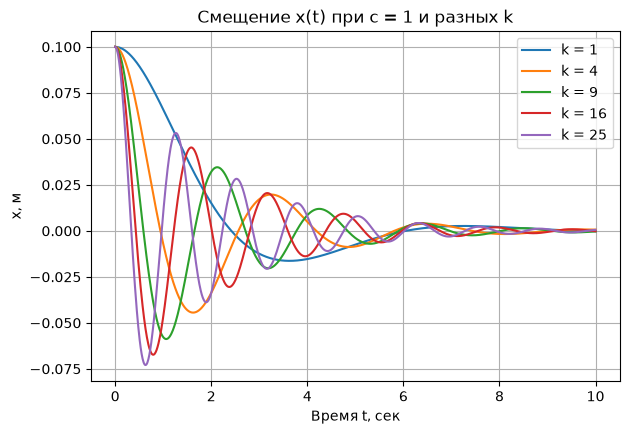

In [173]:
plt.figure(figsize=(15, 10))
plt.subplot(2, 2, 1)

for k in k_values:
    x_func = sp.lambdify(t, sol_k[k], "numpy")
    plt.plot(t_arr, x_func(t_arr), label=f'k = {k}')
plt.title('Смещение x(t) при c = 1 и разных k')
plt.xlabel('Время t, сек')
plt.ylabel('x, м')
plt.grid(True)
plt.legend()

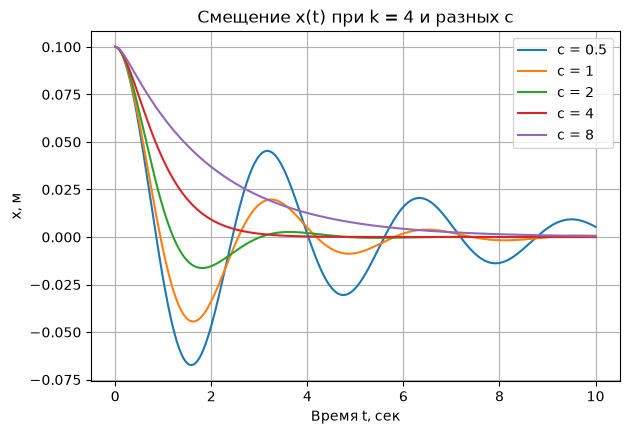

In [174]:
plt.figure(figsize=(15, 10))
plt.subplot(2, 2, 2)
for c in c_values:
    x_func = sp.lambdify(t, sol_c[c], 'numpy')
    plt.plot(t_arr, x_func(t_arr), label=f'c = {c}')
plt.title('Смещение x(t) при k = 4 и разных c')
plt.xlabel('Время t, сек')
plt.ylabel('x, м')
plt.grid(True)
plt.legend()

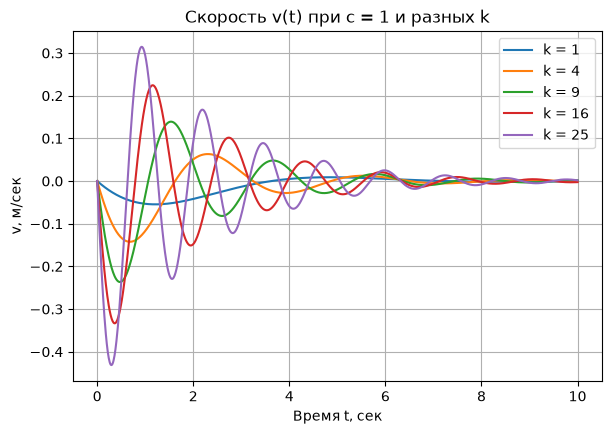

In [175]:
plt.figure(figsize=(15, 10))
plt.subplot(2, 2, 3)

for k in k_values:
    v_expr = sp.diff(sol_k[k], t)
    v_func = sp.lambdify(t, v_expr, "numpy")
    plt.plot(t_arr, v_func(t_arr), label=f'k = {k}')
plt.title('Скорость v(t) при c = 1 и разных k')
plt.xlabel('Время t, сек')
plt.ylabel('v, м/cек')
plt.grid(True)
plt.legend()

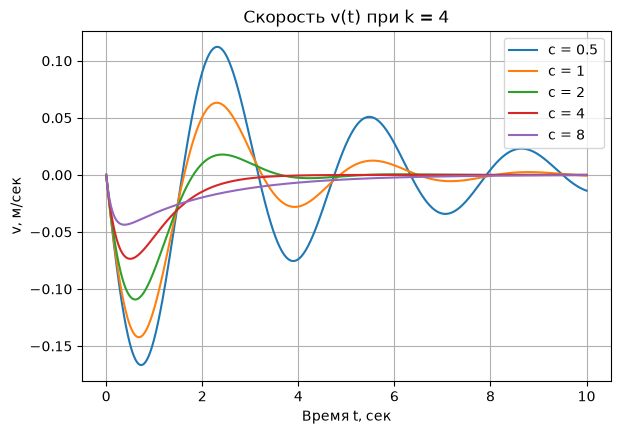

In [176]:
plt.figure(figsize=(15, 10))
plt.subplot(2, 2, 4)
for c in c_values:
    v_expr = sp.diff(sol_c[c], t)
    v_func = sp.lambdify(t, v_expr, 'numpy')
    plt.plot(t_arr, v_func(t_arr), label=f'c = {c}')
plt.title('Скорость v(t) при k = 4')
plt.xlabel('Время t, сек')
plt.ylabel('v, м/сек')
plt.grid(True)
plt.legend()

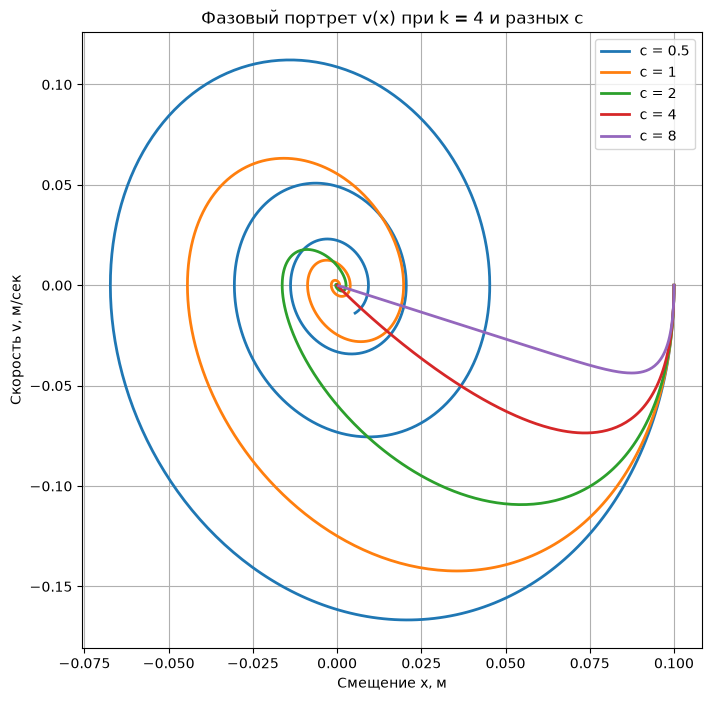

In [177]:
plt.figure(figsize=(8, 8))

for c in c_values:
    x_func = sp.lambdify(t, sol_c[c], 'numpy')
    v_expr = sp.diff(sol_c[c], t)
    v_func = sp.lambdify(t, v_expr, 'numpy')
    plt.plot(x_func(t_arr), v_func(t_arr), label=f'c = {c}', linewidth=2)

plt.title('Фазовый портрет v(x) при k = 4 и разных c')
plt.xlabel('Смещение x, м')
plt.ylabel('Скорость v, м/сек')
plt.grid(True)
plt.legend()

**1. При каком c тележка перестаёт совершать колебания, то есть больше не проходит через положение равновесия?**

Тележка перестает совершать колебания при c >= 2 * sqrt(k * m)

**2. Получите условие c_кр = 2 * sqrt(k * m)**

Из графика, где k = 4, а c меняется, видно, что при c = 4 и при c = 8 тележка не проходит через положение равновесия, что подтверждает формула: c_кр = 2 * sqrt(4 * 1) = 4

**3. Что происходит при c < c_кр, c = c_кр, c > c_кр?**

При слабом затухании (когда c мало) кривая делает много витков, т.к. вязкое трение почти не мешает тележке двигаться, из-за этого тележка может долго ездить вперед-назад, проходя положение равновесия.

При сильном затухании (когда c велико) скорость меняет направление только один раз. Это объясняется тем, что вязкое трение сильно мешает и тележка останавливается, проехав вперед-назад только один раз.

При c < 2 * sqrt(k * m): тележка совершает колебания.
При c = 2 * sqrt(k * m): тележка не совершает колебаний.
При c > 2 * sqrt(k * m): тележка не совершает колебаний и по мере увеличения c скорость движения уменьшается.

**4. В каком режиме тележка быстрее всего возвращается к равновесию?**

По графику, где k = 4, а c меняется видно, что быстрее всего тележка возвращается к равновесию, когда c = 2 * sqrt(k * m).
Это происходит потому, что когда трение создает сопротивление движению ровно столько, сколько нужно для затухания, тележка оказывается в точке 0 быстрее всего. Если трение больше, она тоже приедет в точку 0, но скорость будет гораздо ниже и равновесие будет достигнуто через большее время.